# Calibration of level-2 QC and breakends: exploration per donor

This notebook shows the data behind three calibration decisions:

1. **Noise:** the `noise_excess` cut.
2. **S phase:** the `rt_rho` cut.
3. **Ratio threshold and minimum segment.**

For each, it first shows what the paper (Lin et al. 2024) did and then our data per donor: distributions, relation to depth and batch, and profiles of individual cells.

**Data.** Pilot: 5 donors and 3 bins, with metrics from `scripts/03_cn_qc/cn_qc_metrics.R` and segments from `call_breakends.R`. The profiles are 199 example cells chosen by `select_example_cells.py` (random, per batch, noisiest, highest `rt_rho`, altered and shallow) and exported with `export_relcn.R`. Everything is in `results/pilot_cn/` (git-ignored).

**Conventions.**
- "Enough depth" = `depth_ok`: usable reads ≥ 15 × 2 × bins / 0.91.
- "Batch" = assay × instrument × read length.
- Ratio = segment value / cell median.

## What the paper did

From the Methods and the authors' code (`normalbreastDNA-main/scDNA_analysis/Step1_analysis.R`):

| Step | Lin et al. 2024 (CopyKit 1.0.1) | This project |
|---|---|---|
| Reads | `runVarbin(..., is_paired_end = T, min_bincount = 1)`: **both mates** where paired-end | R1 only |
| Bins | 220 kb variable-size bins (VarBin) | Fixed 200 kb, 500 kb, 1 Mb (QDNAseq) |
| Segmentation | CopyKit default CBS | QDNAseq CBS, `undo.SD = 1` |
| Depth | No explicit threshold | `depth_ok` (15 reads per bin per copy, diploid) |
| Diploid / aneuploid | `findAneuploidCells(simul = F)` | At least one segment with ratio outside 0.7–1.3 |
| Noise | **> 15 breakpoints → out** (`brkp_cutoff <- 15`); `findOutliers(resolution = 0.7, k = 2)` (low correlation with neighbours) | `noise_excess` (excess over Poisson) |
| No events | "Aneuploid" cells with every segment within 0.7–1.3 are removed | Equivalent: not altered |
| Event threshold | `res = 0.3`: gain > 1.3, loss < 0.7 (ratio to the cell mean) | 1.3 / 0.7 to the median |
| Minimum segment | None explicit | ≥ 1 Mb |
| S phase | **Not handled** | `rt_rho` |
| Clustering | UMAP + `findClusters(k_subclones = 60)`; cluster `c0` (outliers) and two specific clusters (c18, c20) removed by hand | Clonal collapse for the enrichment |
| Event unit | Chromosome arm; "expanded" if seen in ≥ 3 cells | Breakend with its interval |

**Reading.** The paper's QC is designed to count arm-level events, not to locate breakends:
- a coarse noise cut (15 breakpoints);
- an outlier filter by correlation;
- the same ratio threshold as ours.

Neither the S phase nor fine noise matters much to call a 1q gain, but both matter for where a breakend falls.

In [1]:
import os, gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
QC = f"{ROOT}/results/pilot_cn/qc"
CAL = f"{ROOT}/results/pilot_cn/calibration"
NB = f"{ROOT}/results/pilot_cn/notebook"
RT_FILE = f"{ROOT}/external/sWGS_relativeCN/bin.annotations/bins_with_replicationTime_50kb.tsv"
BINS = [200, 500, 1000]
DONORS = ["P18", "P20", "P36", "P07", "P08"]          # paper aneuploid fraction, low to high
PAPER = {"P18": 1.0, "P20": 4.8, "P36": 8.2, "P07": 14.3, "P08": 20.9}
DCOL = {"P18": "#4c72b0", "P20": "#55a868", "P36": "#8172b2", "P07": "#c44e52", "P08": "#dd8452"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 9})

def load_qc(b):
    q = pd.read_csv(f"{QC}/cn_qc_{b}kb.tsv", sep="\t")
    c = pd.read_csv(f"{QC}/breakends_{b}kb_cells.tsv", sep="\t")
    q = q.merge(c, on="cell_id", how="left")
    q["altered"] = (q.n_gain_seg + q.n_loss_seg) > 0
    q["batch"] = np.where(q.coassay == 1, "co", "dna") + "|" + q.instrument.str.replace("Illumina ", "") \
                 + "|" + q.read_length.astype(str)
    return q

qc = {b: load_qc(b) for b in BINS}
seg = {b: pd.read_csv(f"{QC}/breakends_{b}kb_segments.tsv", sep="\t", dtype={"chromosome": str}) for b in BINS}
for b in BINS:
    seg[b]["len_mb"] = (seg[b].end - seg[b].start + 1) / 1e6
examples = pd.read_csv(f"{NB}/example_cells.tsv", sep="\t")
print({b: len(q) for b, q in qc.items()}, "cells;", len(examples), "example cells")

{200: 8734, 500: 8734, 1000: 8795} cells; 199 example cells


In [2]:
# profiles of the example cells, and replication timing averaged into each bin
_prof = {}
def profiles(b):
    if b not in _prof:
        p = pd.read_csv(f"{NB}/profiles_{b}kb_bins.tsv.gz", sep="\t", dtype={"chromosome": str})
        p = p[p.chromosome.isin([str(i) for i in range(1, 23)])]
        p["chrn"] = p.chromosome.astype(int)
        _prof[b] = p.sort_values(["cell_id", "chrn", "start"])
    return _prof[b]

rt = pd.read_csv(RT_FILE, sep="\t", usecols=["seqnames", "start", "replicationTime"])
rt["seqnames"] = rt.seqnames.astype(str)
def rt_for(b):
    k = rt.assign(bstart=((rt.start - 1) // (b * 1000)) * b * 1000 + 1)
    return k.groupby(["seqnames", "bstart"]).replicationTime.mean()

def plot_rt_deciles(cell, b, ax):
    # mean bin ratio per decile of replication timing; an S-phase cell rises from late to early
    p = profiles(b)
    p = p[(p.cell_id == cell) & p.use]
    r = (p.copynumber / np.nanmedian(p.segmented)).values
    rv = rt_for(b).reindex(list(zip(p.chromosome, p.start))).values
    k = np.isfinite(r) & np.isfinite(rv)
    dec = pd.qcut(rv[k], 10, labels=False)
    g = pd.Series(r[k]).groupby(dec)
    m, se = g.mean(), g.std() / np.sqrt(g.size())
    ax.errorbar(m.index + 1, m.values, yerr=1.96 * se.values, fmt="o-", color="#55a868", ms=3, capsize=2, elinewidth=.8)
    ax.axhline(1, color="#999999", lw=.6); ax.set_ylim(.8, 1.25)
    ax.set_xlabel("RT decile (1 = late, 10 = early)", fontsize=7); ax.set_ylabel("mean ratio (95% CI)", fontsize=7)

def plot_profile(cell, b, ax, title=None):
    p = profiles(b)
    p = p[(p.cell_id == cell) & p.use]
    if p.empty:
        ax.text(.5, .5, f"{cell}: no data at {b} kb", ha="center", transform=ax.transAxes); return
    med = np.nanmedian(p.segmented)
    x = np.arange(len(p))
    r, s = p.copynumber / med, p.segmented / med
    ax.scatter(x, r.clip(0, 3), s=1.5, c="#9aa5ae", lw=0)
    col = np.where(s > 1.3, "#c44e52", np.where(s < 0.7, "#4c72b0", "#333333"))
    ax.scatter(x, s.clip(0, 3), s=2, c=col, lw=0)
    for y in (0.7, 1.3):
        ax.axhline(y, color="#c9a227", lw=.6, ls="--")
    edges = np.flatnonzero(np.diff(p.chrn.values)) + 0.5
    for e in edges:
        ax.axvline(e, color="#dddddd", lw=.5)
    ax.set_ylim(0, 3); ax.set_xlim(0, len(p)); ax.set_xticks([])
    q = qc[b].set_index("cell_id").loc[cell]
    ax.set_title(title or f"{cell} · {b} kb · {int(q.reads/1e3)}k reads · noise {q.noise_excess:.2f} · rt_rho {q.rt_rho:.2f}",
                 fontsize=8, loc="left")

## Concepts: replication timing and `noise_excess`

The figures in this section come from `scripts/docs/concept_figures.py`, the same code that draws them in the technical report.

### Replication timing (RT)

During S phase, each genomic region is copied at a typical time:
- **Early:** GC-rich, open regions with active genes.
- **Late:** GC-poor, heterochromatic regions with very large genes.

It is measured with Repli-seq (BrdU in early and late fractions) or by comparing the CN of S-phase cells with that of G1 cells.

The file `bins_with_replicationTime_50kb.tsv` (`sWGS_relativeCN` pipeline) has 49,697 windows of 50 kb.
- Values from 11.6 to 82.2; high values are early (Spearman with GC = 0.69).
- **Its source is not documented:** it looks like Repli-seq from an ENCODE line, not verified, and it is not breast epithelium.
- Each of our bins gets the mean of the 50 kb windows it contains.

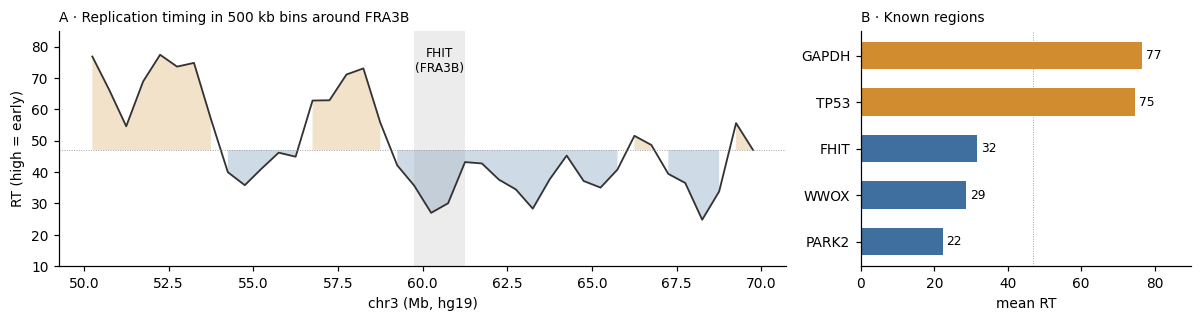

In [3]:
import sys
sys.path.insert(0, f"{ROOT}/scripts/docs")
import concept_figures as cf
cf.fig_rt_regions(); plt.show()

*A:* RT per 500 kb bin on chr3:50–70 Mb (ochre = early, blue = late; grey = FHIT / FRA3B). *B:* mean RT of known regions: housekeeping genes are early and CFS genes late.

### Why S phase matters for the CFS question

A diploid cell halfway through S phase has 4 copies of early regions and 2 of late ones. Relative to its mean (≈ 3):

```
early 4/3 = 1.33  > 1.3  → "gain"
late  2/3 = 0.67  < 0.7  → "loss"
```

On chr3 this gives a "gain" at 57–58.5 Mb and a "loss" over FHIT: **a false breakend right at the edge of FRA3B**. Because CFS are late-replicating and often lie next to early regions, S phase creates breakends at CFS edges.

`rt_rho` = Spearman correlation between each bin's relative CN (corrected count / median, unsegmented) and its RT.
- In G1 ≈ 0 (P18 p99: 0.02–0.07).
- In S phase, positive.
- A GC bias also makes it positive, because RT and GC correlate.

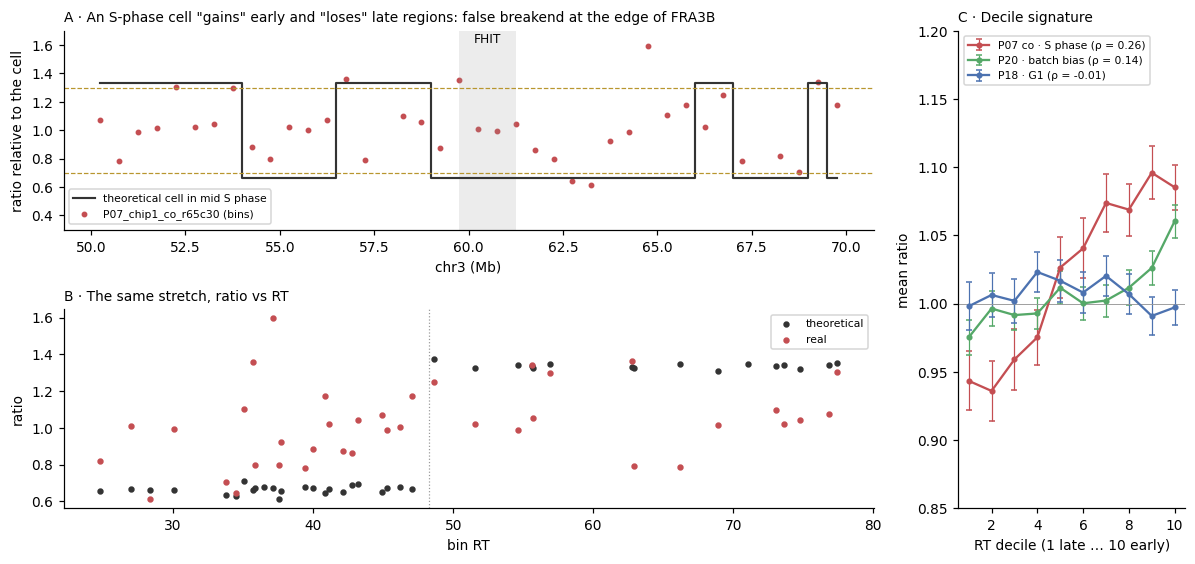

In [4]:
cf.fig_sphase(); plt.show()

*A:* black, the theoretical cell; red, P07_chip1_co_r65c30 (`rt_rho` 0.26) on the same stretch. *B:* ratio versus RT. *C:* mean ratio per RT decile across the genome.
- **S phase** (P07 co): steep slope, ~0.94 → 1.10.
- **Batch bias** (P20): shallow slope.
- **G1** (P18): flat.

The real cell is smoother than the theoretical one (early or late S phase): it does not cross 1.3 / 0.7 as a block, but it adds steps.

### `noise_excess`: origin and calculation

It is a **metric defined in this project** (`cn_qc_metrics.R`). It combines two common ideas in scDNA-seq:
- comparing neighbouring bins, as MAPD does (Ginkgo, 10x CNV);
- measuring overdispersion relative to Poisson.

It adds a normalisation by each bin's depth.

With x = corrected count and s = mean of the segment the bin belongs to:

```
d_i = (x[i+1] − x[i]) / √(s[i+1] + s[i])
noise_excess = 1.4826 × MAD(d)
```

If bins are Poisson, Var(x[i+1] − x[i]) = s[i+1] + s[i], so d has variance 1 at any depth. With variance φ·s, noise_excess ≈ √φ.
- **Taking neighbour differences** removes the CN level: an arm gain does not count as noise.
- **The MAD** ignores the few pairs that cross a real breakend.

Example with λ = 50:

```
pure Poisson:      x = 47 55 44 52 49 → diff +8 −11 +8 −3   → ÷10 → 0.8 −1.1 0.8 −0.3 → SD ≈ 1
variance 2.25 λ:   x = 41 61 38 58 46 → diff +20 −23 +20 −12 → ÷10 → 2.0 −2.3 2.0 −1.2 → SD ≈ 1.5
```

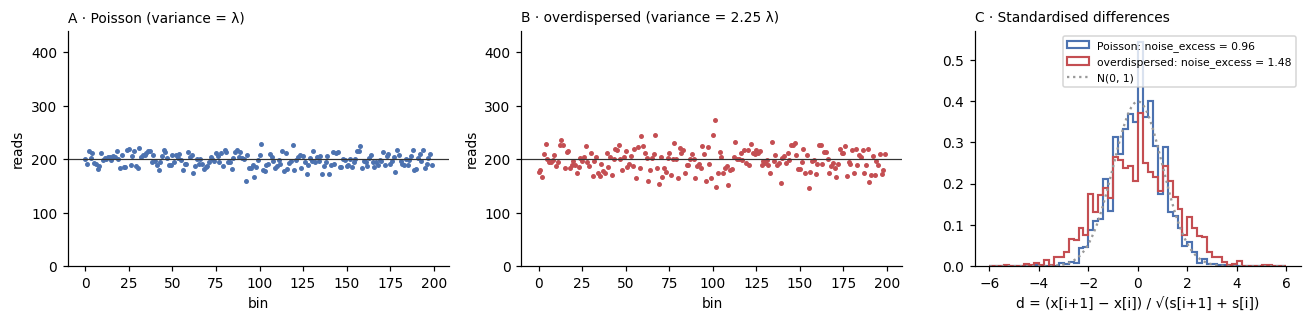

In [5]:
cf.fig_noise_toy(); plt.show()

Simulation with λ = 200. With small integer counts the MAD is imprecise (at λ = 50, pure Poisson gives 0.89); real corrected counts are continuous, so this does not occur in the data.

**Why the raw SD is not enough.** The raw SD falls with depth, so a cut on it would exclude shallow cells, that is, batches. `noise_excess` stays near 1. It rises slightly in the deepest cells, where systematic noise (GC waves, RT) weighs more against an already small Poisson noise. This is why the P18 p99 grows with bin size (1.20 → 1.32 → 1.39).

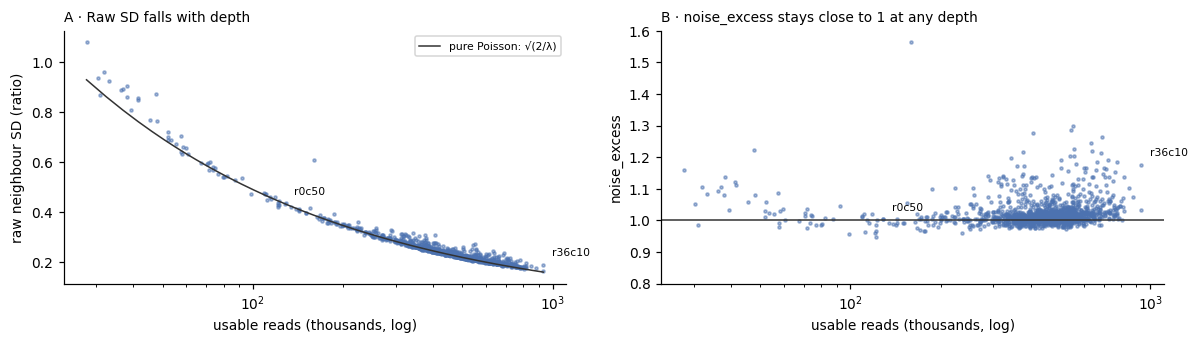

In [6]:
cf.fig_noise_depth(); plt.show()

**How to read it: effective reads ≈ usable reads / noise_excess².** Noise k times the Poisson level is equivalent to having k² times fewer reads.

| Cell (500 kb) | Reads | noise_excess | Effective |
|---|---|---|---|
| P18_chip1_dna_r13c3 | 256k | 1.03 | 242k |
| P07_chip1_co_r65c30 | 360k | 1.57 | 145k (exactly the 500 kb threshold) |
| P07_chip1_co_r30c35 | 600k | 3.76 | **43k** (below even the 1 Mb threshold) |

`depth_ok` measures the number of reads; `noise_excess`, how much of that number is useful information.

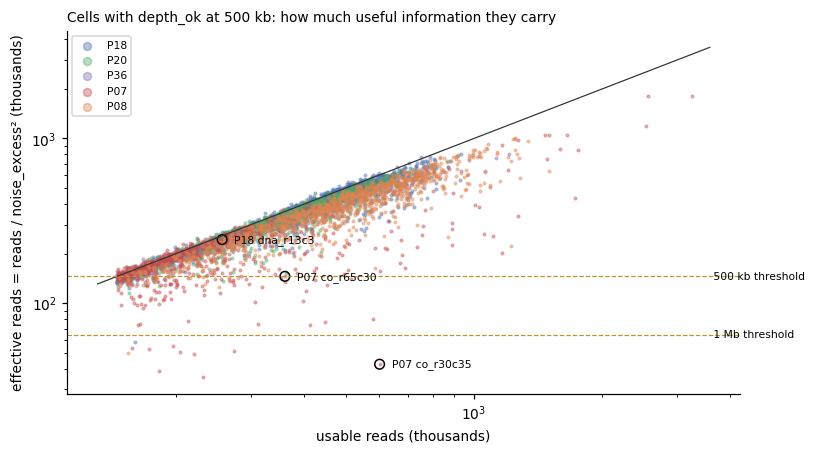

In [7]:
cf.fig_effective_reads(); plt.show()

**What it does not measure.** A slow wave spanning many bins barely changes between neighbours. `rt_rho` and the number of segments cover that:
- `noise_excess` measures fast variation (amplification, library);
- `rt_rho` measures slow variation organised by replication domains, which follows the same geography as CFS.

## 0 · Overview per donor: depth and retention

Before the cuts: how many usable reads each donor has and what fraction passes depth in each bin. The remaining plots show only cells with enough depth in that bin, unless stated otherwise.

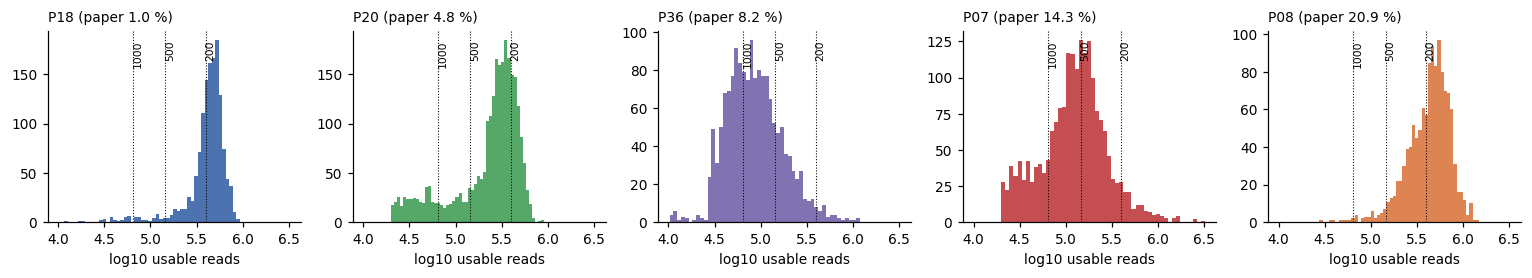

depth_ok_pct             altered_pct            
bin_kb         200   500   1000        200   500   1000
donor                                                  
P18            68.7  95.4  97.9         2.4   1.7   1.4
P20            23.8  77.4  86.3         7.6   5.5   5.2
P36             2.6  21.7  62.5         9.8   7.3   6.8
P07             7.1  44.0  77.9        13.5   9.6   9.4
P08            62.7  96.6  99.3        33.4  23.8  20.1

In [8]:
need = {200: 396165, 500: 145286, 1000: 64022}
fig, axes = plt.subplots(1, 5, figsize=(14, 2.6), sharex=True)
for ax, d in zip(axes, DONORS):
    g = qc[500][qc[500].donor == d]
    ax.hist(np.log10(g.reads), bins=50, color=DCOL[d])
    for b, n in need.items():
        ax.axvline(np.log10(n), color="k", lw=.7, ls=":"); ax.text(np.log10(n), ax.get_ylim()[1]*.95, f"{b}", fontsize=7, rotation=90, va="top")
    ax.set_title(f"{d} (paper {PAPER[d]} %)", loc="left"); ax.set_xlabel("log10 usable reads")
plt.tight_layout(); plt.show()

rows = []
for b in BINS:
    for d in DONORS:
        g = qc[b][qc[b].donor == d]; ok = g[g.depth_ok == 1]
        rows.append(dict(bin_kb=b, donor=d, cells=len(g), depth_ok_pct=100*len(ok)/len(g),
                         altered_pct=100*ok.altered.mean(), paper_pct=PAPER[d]))
display(pd.DataFrame(rows).pivot(index="donor", columns="bin_kb", values=["depth_ok_pct", "altered_pct"]).round(1).loc[DONORS])

*Method.* Histogram of usable reads per cell (those QDNAseq counts). Dotted lines are the diploid threshold of each bin. "altered_pct" = % of cells with enough depth that have a retained segment with ratio > 1.3 or < 0.7. *Limitation:* the paper column uses a different definition.

## 1 · Noise

**Question.** Which noise cut removes cells whose profile is not reliable for locating breakends, without removing whole batches?

**Paper.** More than 15 breakpoints → out, and `findOutliers` by correlation. It does not measure noise between bins.

### 1.1 `noise_excess` per donor and batch

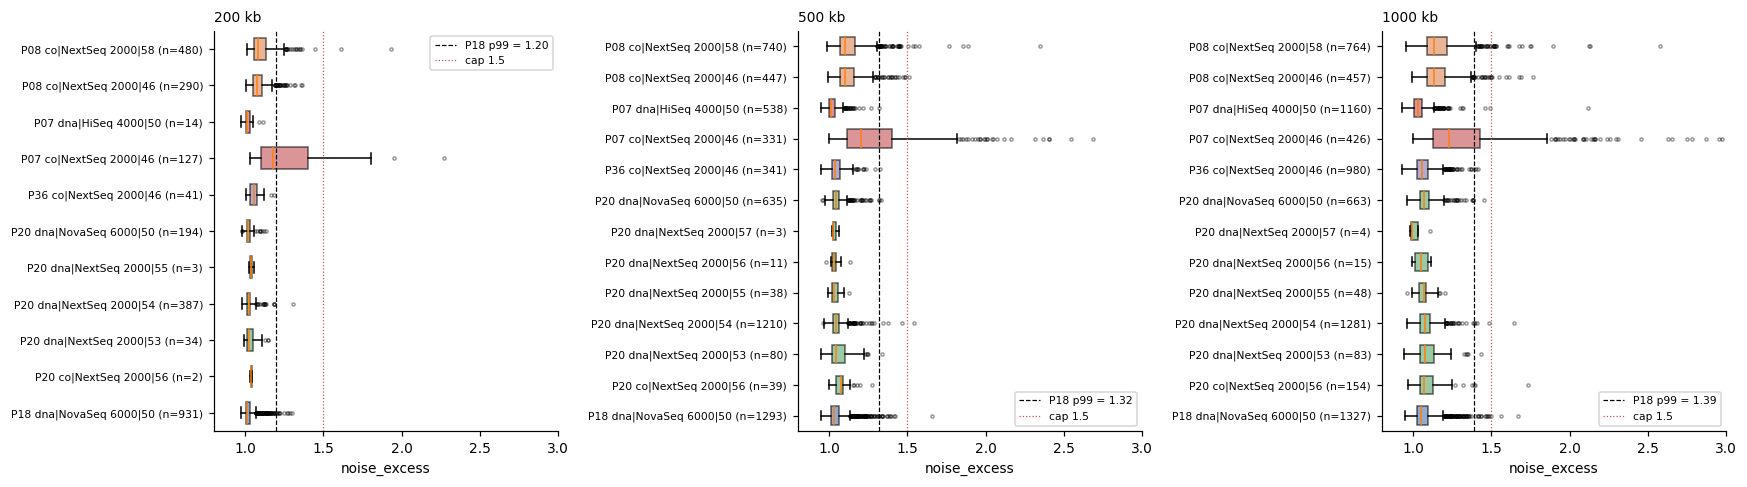

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, b in zip(axes, BINS):
    ok = qc[b][qc[b].depth_ok == 1]
    groups = [(d, bt) for d in DONORS for bt in sorted(ok[ok.donor == d].batch.unique())]
    data = [ok[(ok.donor == d) & (ok.batch == bt)].noise_excess.values for d, bt in groups]
    bp = ax.boxplot(data, vert=False, showfliers=True, flierprops=dict(ms=2, alpha=.4), widths=.6, patch_artist=True)
    for patch, (d, _) in zip(bp["boxes"], groups):
        patch.set_facecolor(DCOL[d]); patch.set_alpha(.6)
    ax.set_yticks(range(1, len(groups)+1), [f"{d} {bt} (n={len(x)})" for (d, bt), x in zip(groups, data)], fontsize=7)
    p18 = ok[ok.donor == "P18"].noise_excess.quantile(.99)
    ax.axvline(p18, color="k", lw=.8, ls="--", label=f"P18 p99 = {p18:.2f}")
    ax.axvline(1.5, color="#c44e52", lw=.8, ls=":", label="cap 1.5")
    ax.set_xlim(.8, 3); ax.set_title(f"{b} kb", loc="left"); ax.set_xlabel("noise_excess"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

*Method.* `noise_excess` = robust SD (MAD) of differences between neighbouring bins of the corrected count, divided by √(sum of their segment means). It is 1 for pure Poisson noise. Only cells with enough depth in that bin. *What to look for:* whether the shift belongs to a whole donor or to one batch within a donor.

### 1.2 Does noise depend on depth?

If the metric is well normalised, it should not rise or fall with depth. A slope would mean the cut excludes by depth (that is, by batch).

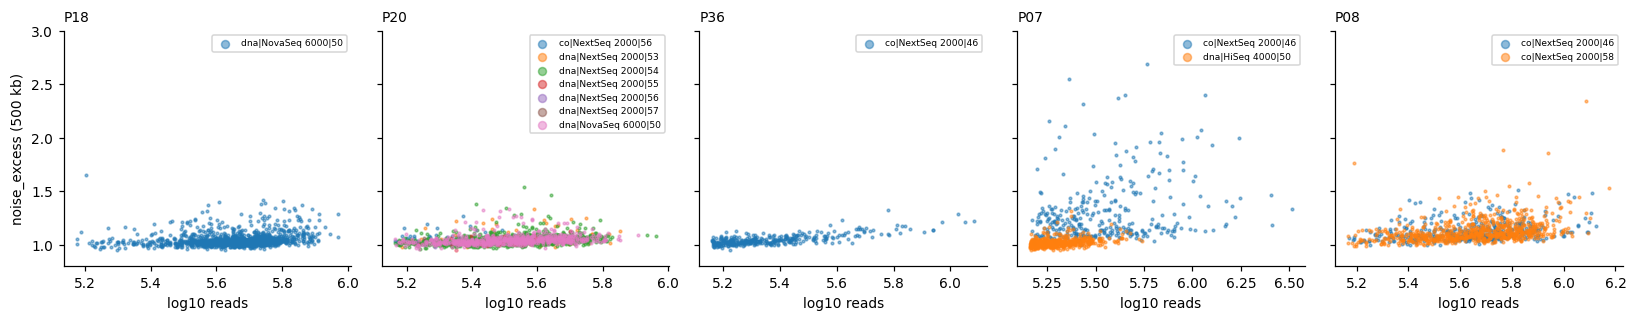

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3), sharey=True)
ok = qc[500][qc[500].depth_ok == 1]
for ax, d in zip(axes, DONORS):
    g = ok[ok.donor == d]
    for bt, gg in g.groupby("batch"):
        ax.scatter(np.log10(gg.reads), gg.noise_excess, s=3, alpha=.5, label=bt)
    ax.set_title(d, loc="left"); ax.set_xlabel("log10 reads"); ax.set_ylim(.8, 3); ax.legend(fontsize=6, markerscale=3)
axes[0].set_ylabel("noise_excess (500 kb)")
plt.tight_layout(); plt.show()

### 1.3 Profiles: what noise looks like

Per row: P07 co-assay (the noisiest), P07 DNA-only (random), P18 (random). Same bin (500 kb). Grey: ratio of each bin. Black, red and blue: neutral, gain and loss segment. Yellow lines: 0.7 and 1.3.

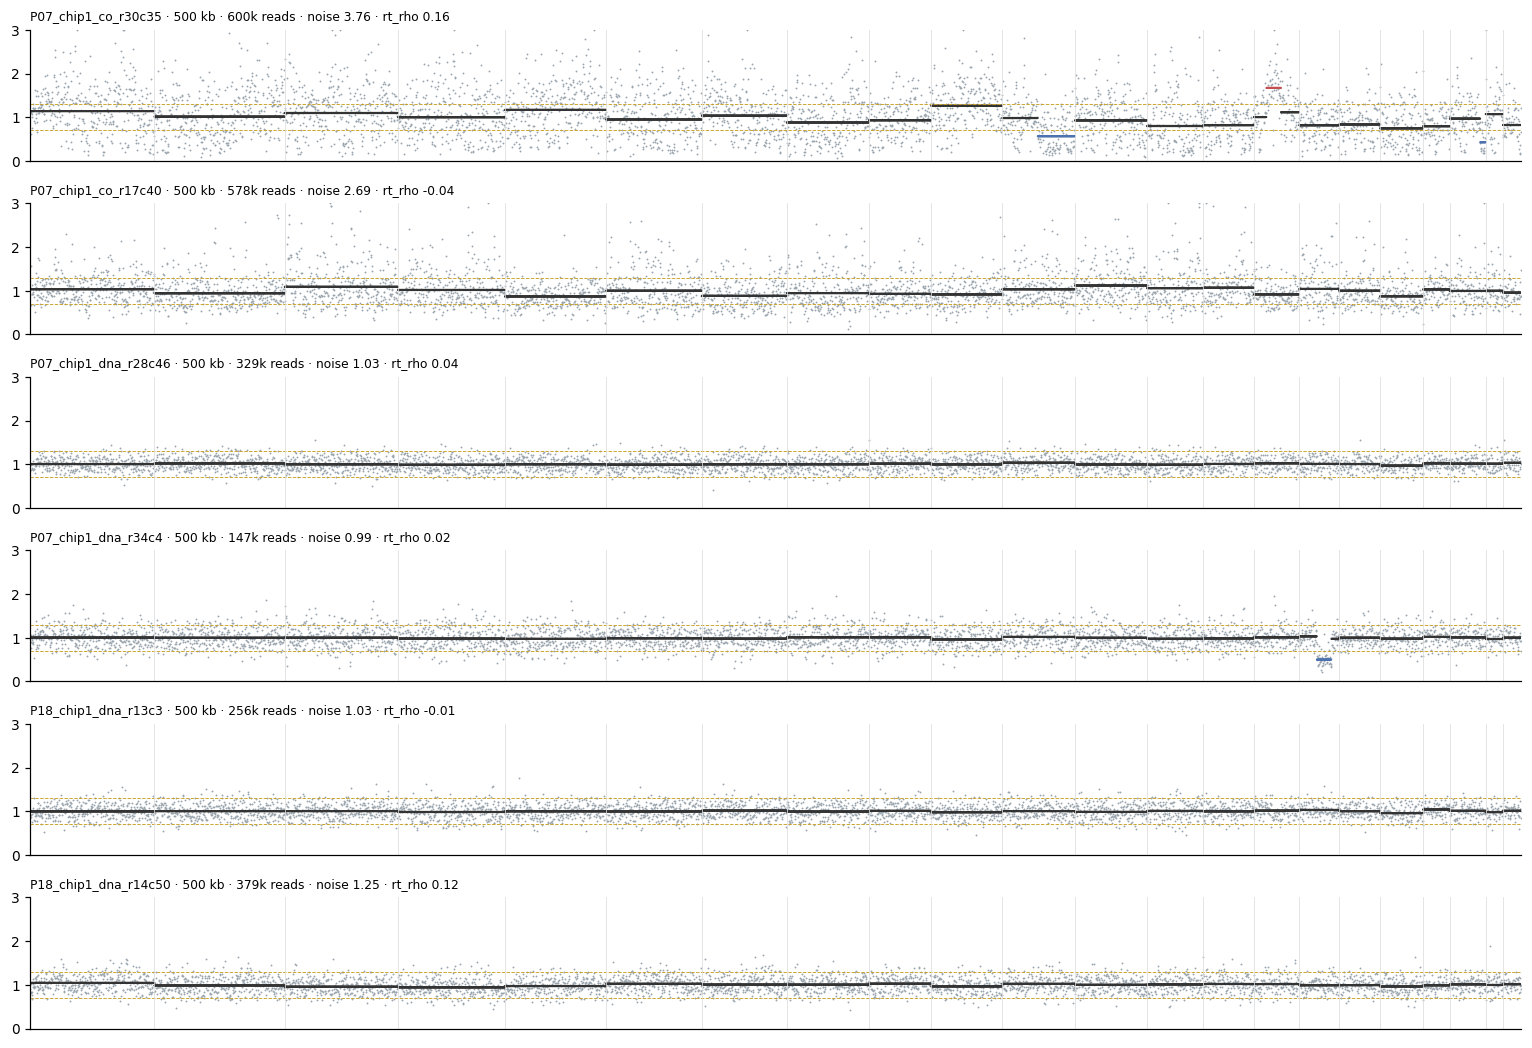

In [11]:
q5 = qc[500].set_index("cell_id")
ex = examples.set_index("cell_id")
pick = []
p07co = q5[(q5.donor == "P07") & (q5.coassay == 1) & (q5.depth_ok == 1)].noise_excess
pick += list(p07co.nlargest(2).index)
pick += list(q5[(q5.donor == "P07") & (q5.coassay == 0) & (q5.depth_ok == 1)].index.intersection(ex.index)[:2])
pick += list(q5[(q5.donor == "P18") & (q5.depth_ok == 1)].index.intersection(ex.index)[:2])
fig, axes = plt.subplots(len(pick), 1, figsize=(14, 1.6*len(pick)))
for ax, c in zip(axes, pick):
    plot_profile(c, 500, ax)
plt.tight_layout(); plt.show()

### 1.4 The paper's criterion: number of segments

Our approximation to CopyKit's "breakpoint_count" is the number of segment changes per cell, before the minimum-segment filter (segments − chromosomes with data). Line: the paper's cut of 15. *Limitation:* CopyKit segments with other parameters and bins, so the number is not directly comparable; it shows the order of magnitude.

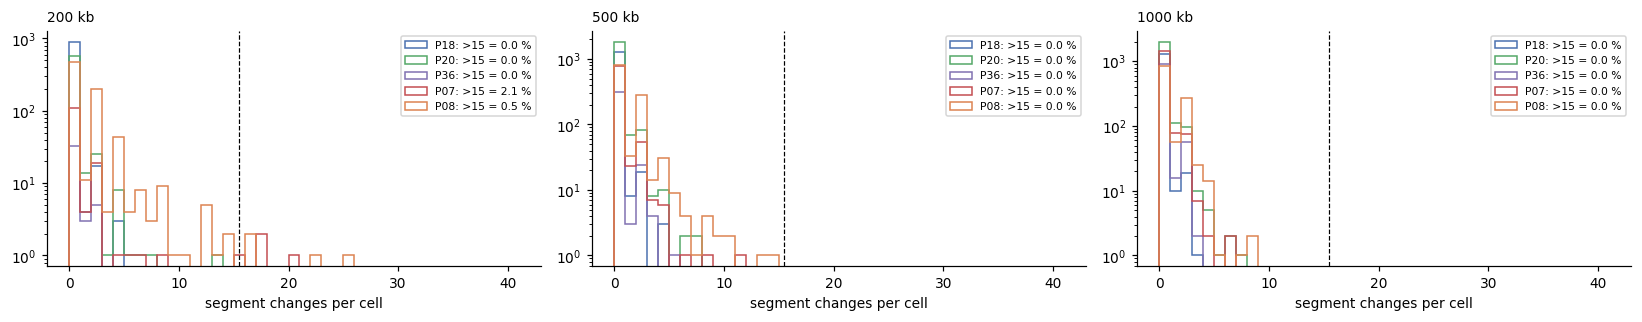

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, b in zip(axes, BINS):
    s = seg[b].groupby("cell_id").agg(nseg=("rel", "size"), nchr=("chromosome", "nunique"))
    s["brk"] = s.nseg - s.nchr
    ok = qc[b][qc[b].depth_ok == 1].merge(s, left_on="cell_id", right_index=True)
    for d in DONORS:
        v = ok[ok.donor == d].brk
        ax.hist(v.clip(upper=40), bins=range(0, 42), histtype="step", color=DCOL[d], label=f"{d}: >15 = {100*(v>15).mean():.1f} %")
    ax.axvline(15.5, color="k", ls="--", lw=.8); ax.set_yscale("log")
    ax.set_title(f"{b} kb", loc="left"); ax.set_xlabel("segment changes per cell"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

### 1.5 Exclusion under each cut option

From `results/pilot_cn/calibration/cut_options_exclusion.tsv` (`calibration_tables.py`). "Batch-relative" = the value divided by its batch median exceeds the P18 tolerance (p99 / median).

In [13]:
x = pd.read_csv(f"{CAL}/cut_options_exclusion.tsv", sep="\t")
x["group"] = x.donor + np.where(x.coassay == 1, " co", " dna")
display(x[x.option.str.startswith("noise")].pivot_table(index=["option", "bin_kb"], columns="group", values="excluded_pct").round(1))

group                        P07 co  P07 dna  P08 co  P18 dna  P20 co  \
option               bin_kb                                             
noise_batch_relative 200       26.0      0.0     2.2      1.1     0.0   
                     500       16.3      0.2     2.2      1.0     0.0   
                     1000      15.7      0.3     2.2      1.1     0.6   
noise_cap_1.5        200       17.3      0.0     0.3      0.0     0.0   
                     500       17.5      0.0     0.8      0.1     0.0   
                     1000      21.4      0.1     2.2      0.2     0.6   
noise_global_p18p99  200       45.7      0.0     8.8      1.1     0.0   
                     500       33.2      0.2     5.0      1.0     0.0   
                     1000      29.8      0.3     5.6      1.1     2.0   

group                        P20 dna  P36 co  
option               bin_kb                   
noise_batch_relative 200         0.2     0.0  
                     500         0.3     0.0  
                     1000        0.2     0.3  
noise_cap_1.5        200         0.0     0.0  
                     500         0.0     0.0  
                     1000        0.0     0.0  
noise_global_p18p99  200         0.2     0.0  
                     500         0.4     0.3  
                     1000        0.3     0.3

## 2 · S phase

**Question.** Which cells carry the replication signature (more copies in early regions) and should be removed?

**Paper.** S phase is not handled. At arm level, an S-phase cell rarely crosses 1.3 / 0.7 over a whole arm. For locating breakends it does matter: its steps fall at replication transitions, next to late CFS.

### 2.1 `rt_rho` per donor

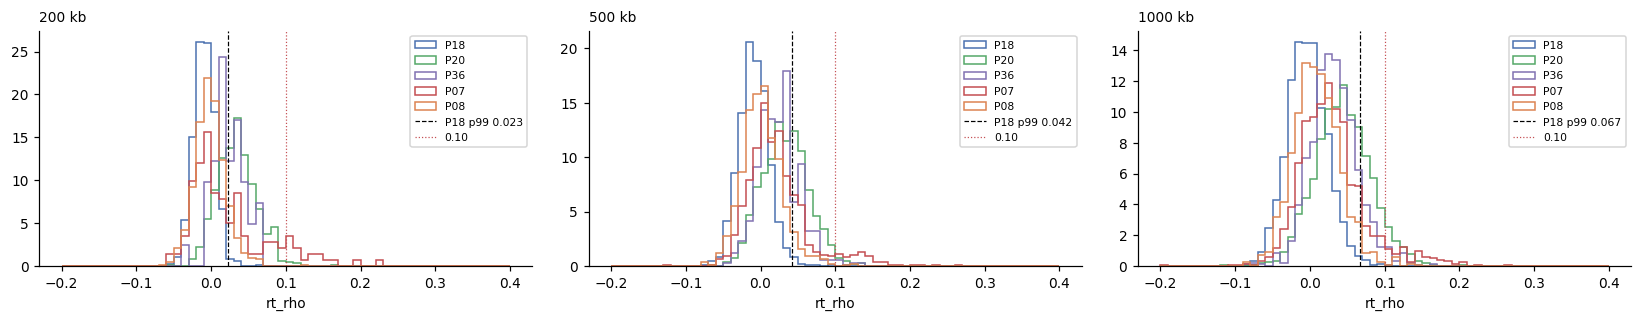

count    50%    95%    99%
donor batch                                           
P07   co|NextSeq 2000|46    331.0  0.025  0.148  0.197
      dna|HiSeq 4000|50     538.0  0.012  0.055  0.069
P08   co|NextSeq 2000|46    447.0  0.001  0.048  0.081
      co|NextSeq 2000|58    740.0  0.001  0.047  0.078
P18   dna|NovaSeq 6000|50  1293.0 -0.009  0.025  0.042
P20   co|NextSeq 2000|56     39.0  0.051  0.087  0.092
      dna|NextSeq 2000|53    80.0  0.006  0.064  0.075
      dna|NextSeq 2000|54  1210.0  0.035  0.085  0.110
      dna|NextSeq 2000|55    38.0  0.035  0.084  0.093
      dna|NextSeq 2000|56    11.0  0.031  0.078  0.081
      dna|NextSeq 2000|57     3.0  0.054  0.061  0.062
      dna|NovaSeq 6000|50   635.0  0.032  0.086  0.112
P36   co|NextSeq 2000|46    341.0  0.025  0.071  0.101

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3), sharey=False)
for ax, b in zip(axes, BINS):
    ok = qc[b][qc[b].depth_ok == 1]
    for d in DONORS:
        ax.hist(ok[ok.donor == d].rt_rho, bins=np.linspace(-.2, .4, 61), histtype="step", color=DCOL[d], label=d, density=True)
    p18 = ok[ok.donor == "P18"].rt_rho.quantile(.99)
    ax.axvline(p18, color="k", ls="--", lw=.8, label=f"P18 p99 {p18:.3f}"); ax.axvline(.10, color="#c44e52", ls=":", lw=.8, label="0.10")
    ax.set_title(f"{b} kb", loc="left"); ax.set_xlabel("rt_rho"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

ok = qc[500][qc[500].depth_ok == 1]
display(ok.groupby(["donor", "batch"]).rt_rho.describe(percentiles=[.5, .95, .99])[["count", "50%", "95%", "99%"]].round(3))

*Method.* `rt_rho` = Spearman between each bin's relative CN and replication timing (50 kb, averaged into the bin; high values = early replication). *What to look for:*
- An S-phase cell is a right-hand tail.
- A whole donor shifted (P20) indicates a batch bias (GC, amplification), not S phase.

### 2.2 Profiles with RT

The 3 cells with the highest `rt_rho` in P07 and P20, and one P18 cell as reference. On the right, the mean bin ratio per replication-timing decile. An S-phase cell rises monotonically from late to early (halfway through S phase, up to ~1.3–1.5 times); a G1 cell is flat at 1. A shallow, uniform slope across a whole donor (P20) points to a GC or amplification bias, not replication.

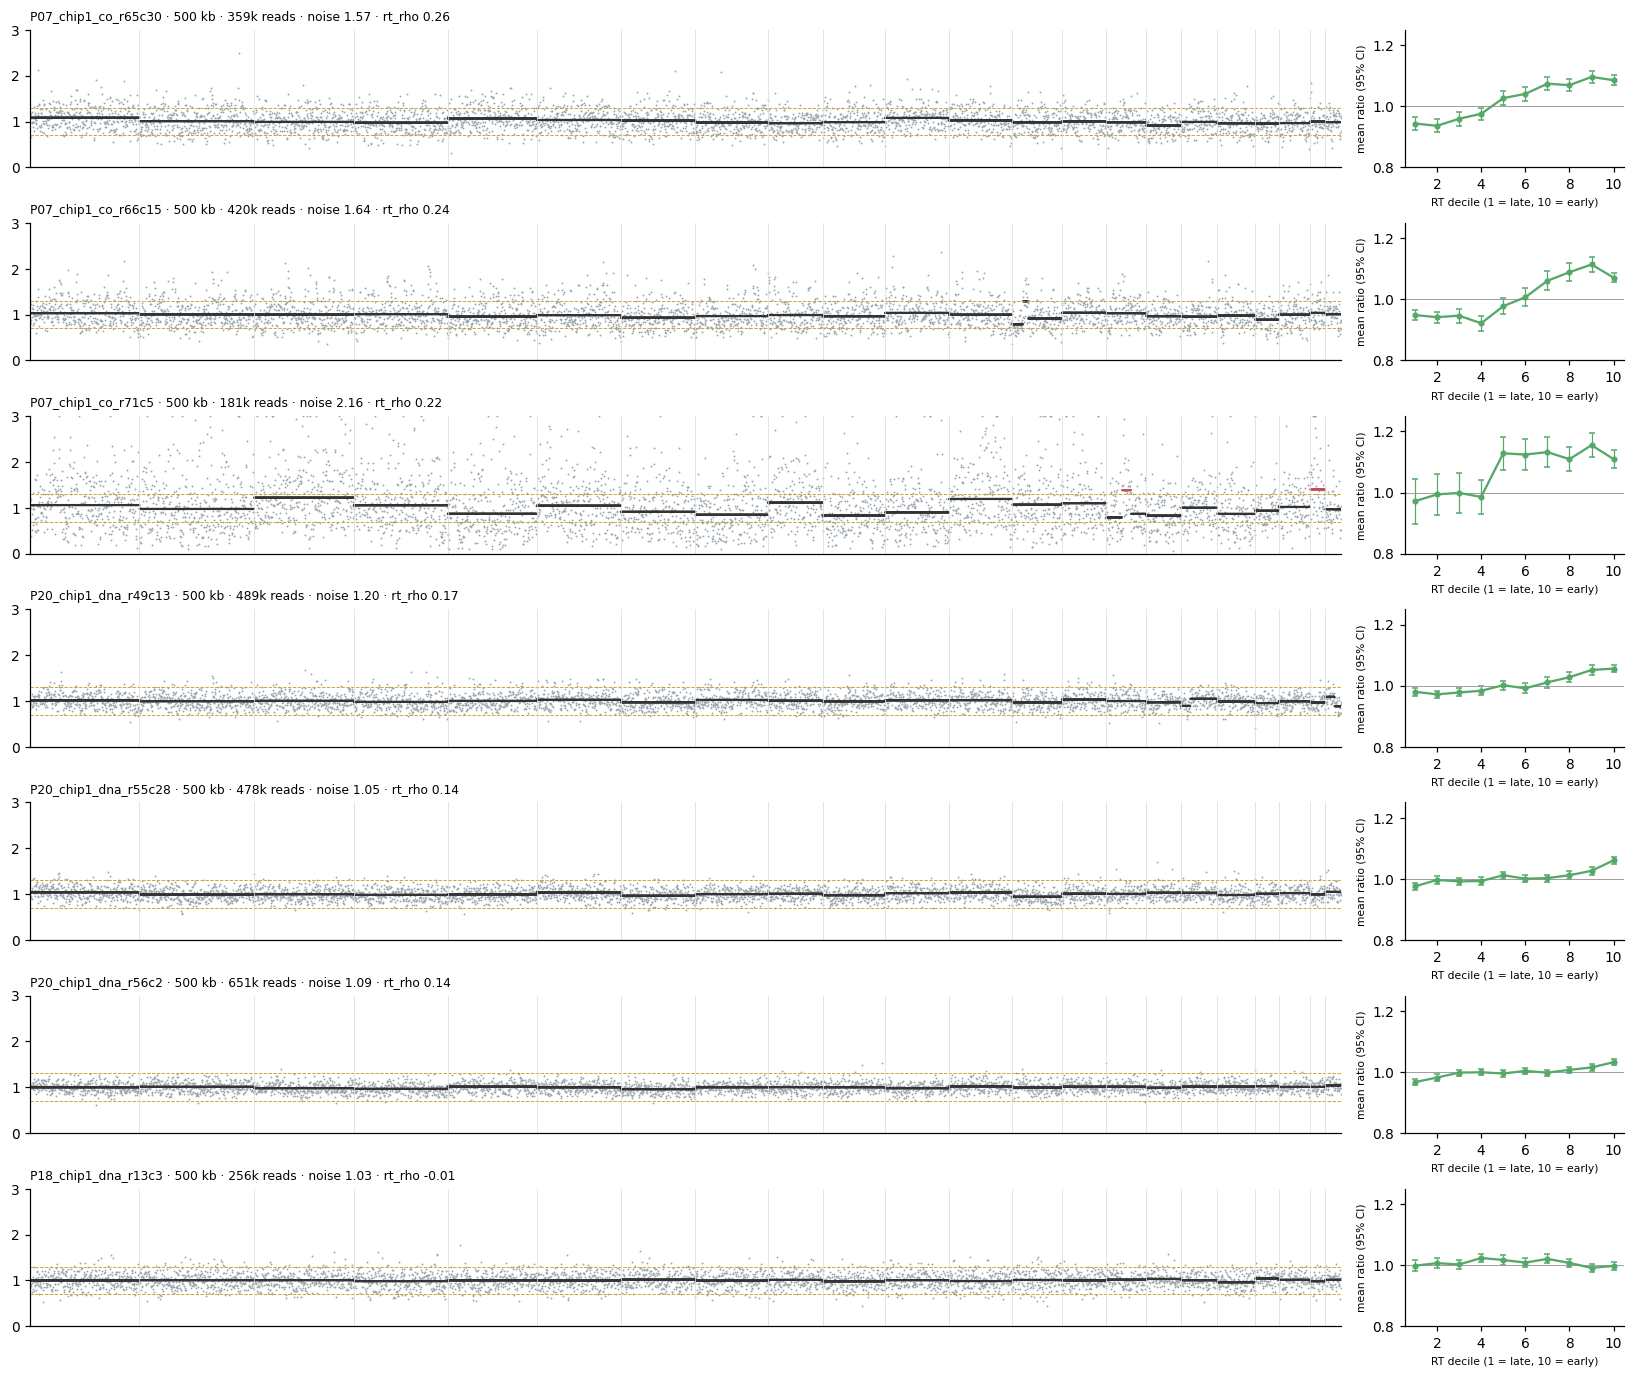

In [15]:
pick = []
for d in ["P07", "P20"]:
    pick += list(q5[(q5.donor == d) & (q5.depth_ok == 1)].rt_rho.nlargest(3).index)
pick += list(q5[(q5.donor == "P18") & (q5.depth_ok == 1)].index.intersection(ex.index)[:1])
fig, axes = plt.subplots(len(pick), 2, figsize=(15, 1.8*len(pick)), gridspec_kw={"width_ratios": [6, 1]})
for (ax, axd), c in zip(axes, pick):
    plot_profile(c, 500, ax); plot_rt_deciles(c, 500, axd)
plt.tight_layout(); plt.show()

### 2.3 S phase or noise? `rt_rho` versus `noise_excess`

If cells with high `rt_rho` are also noisy, the two cuts partly remove the same cells.

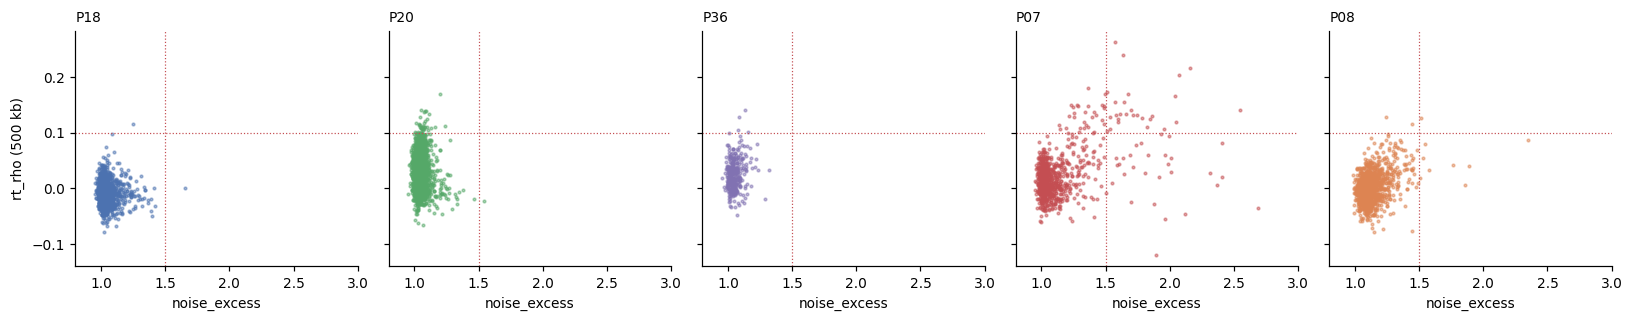

group                    P07 co  P07 dna  P08 co  P18 dna  P20 co  P20 dna  \
option           bin_kb                                                      
rt_batch_centred 200       29.9     14.3     6.0      1.0     0.0     12.1   
                 500       22.7      2.4     4.1      1.0     0.0      5.0   
                 1000      20.4      1.5     2.1      1.0     3.2      3.1   
rt_fixed_0.10    200       13.4      0.0     0.1      0.0     0.0      1.0   
                 500       17.2      0.0     0.2      0.1     0.0      1.7   
                 1000      22.5      0.8     0.9      0.2    10.4      6.5   
rt_p18p99        200       40.2     14.3    10.8      1.0   100.0     65.5   
                 500       37.2     12.6     6.8      1.0    61.5     38.1   
                 1000      32.9      7.7     3.7      1.0    33.8     26.2   

group                    P36 co  
option           bin_kb          
rt_batch_centred 200        9.8  
                 500        3.5  
                 1000       2.2  
rt_fixed_0.10    200        0.0  
                 500        1.2  
                 1000       2.6  
rt_p18p99        200       48.8  
                 500       23.2  
                 1000      13.0

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3), sharey=True, sharex=True)
for ax, d in zip(axes, DONORS):
    g = ok[ok.donor == d]
    ax.scatter(g.noise_excess, g.rt_rho, s=3, alpha=.5, color=DCOL[d])
    ax.axhline(.10, color="#c44e52", ls=":", lw=.8); ax.axvline(1.5, color="#c44e52", ls=":", lw=.8)
    ax.set_title(d, loc="left"); ax.set_xlabel("noise_excess"); ax.set_xlim(.8, 3)
axes[0].set_ylabel("rt_rho (500 kb)")
plt.tight_layout(); plt.show()
display(x[x.option.str.startswith("rt")].pivot_table(index=["option", "bin_kb"], columns="group", values="excluded_pct").round(1))

## 3 · Ratio threshold and minimum segment

**Question.** Which threshold separates altered segments from noise without losing real events? Is a minimum segment needed?

**Paper.** Gain > 1.3 and loss < 0.7 relative to the cell mean, no explicit minimum segment.

### 3.1 Distribution of segment ratios

Each segment is weighted by its length. Expected peaks are 1 (neutral) and 1.5 / 0.5 (one copy more or less in a diploid cell). A good threshold falls in the valley between peaks.

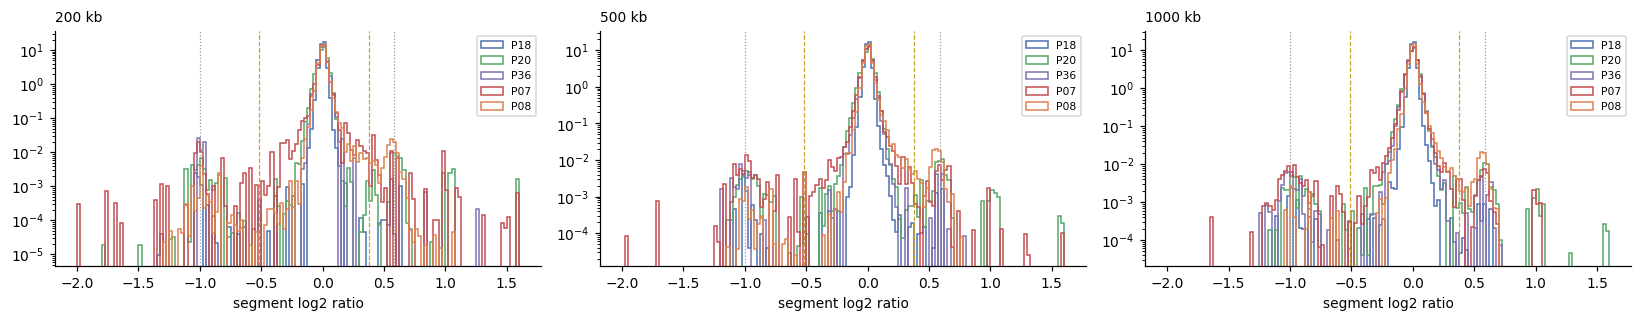

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, b in zip(axes, BINS):
    okc = set(qc[b].cell_id[qc[b].depth_ok == 1])
    s = seg[b][seg[b].cell_id.isin(okc)].merge(qc[b][["cell_id", "donor"]], on="cell_id")
    for d in DONORS:
        g = s[s.donor == d]
        ax.hist(np.log2(g.rel.clip(.2, 3)), bins=np.linspace(-2, 1.6, 145), weights=g.len_mb, histtype="step",
                color=DCOL[d], label=d, density=True)
    for v in (0.7, 1.3):
        ax.axvline(np.log2(v), color="#c9a227", ls="--", lw=.8)
    for v in (0.5, 1.5):
        ax.axvline(np.log2(v), color="#999999", ls=":", lw=.8)
    ax.set_yscale("log"); ax.set_title(f"{b} kb", loc="left"); ax.set_xlabel("segment log2 ratio"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

*Method.* All segments (before the minimum-segment filter) of cells with enough depth, weighted by length in Mb. Log y scale to show the tails. Yellow: 0.7 / 1.3; grey: 0.5 / 1.5.

### 3.2 Threshold sweep: specificity in P18 and sensitivity on the P08 6q clone

From `threshold_sweep.tsv`. Cells passing depth, noise ≤ P18 p99 and `rt_rho` ≤ 0.10. The clone reference is the 215 P08 cells with the 6q gain at 1 Mb under the default rule, so its recall at 1.3 / 0.7 at 1 Mb is 100% by construction.

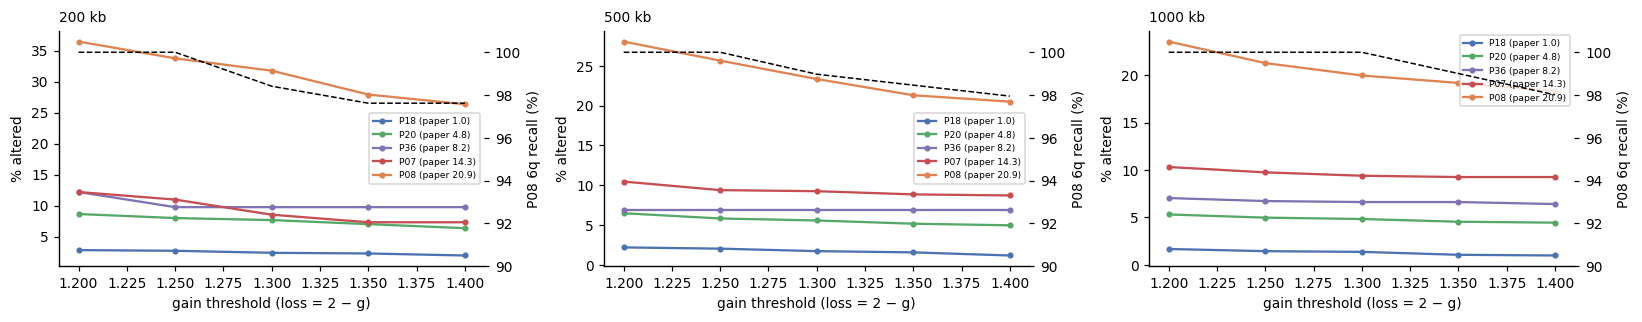

min_seg      bins5   mb1  mb1_bins3
bin_kb gain                        
200    1.20   2.82  2.82       2.82
       1.25   2.71  2.71       2.71
       1.30   2.39  2.39       2.39
       1.35   2.28  2.28       2.28
       1.40   1.95  1.95       1.95
500    1.20   2.11  2.19       2.19
       1.25   1.96  2.03       2.03
       1.30   1.64  1.72       1.72
       1.35   1.49  1.56       1.56
       1.40   1.17  1.17       1.17
1000   1.20   1.60  1.68       1.68
       1.25   1.37  1.45       1.45
       1.30   1.30  1.37       1.37
       1.35   1.07  1.07       1.07
       1.40   0.99  0.99       0.99

In [18]:
sw = pd.read_csv(f"{CAL}/threshold_sweep.tsv", sep="\t")
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, b in zip(axes, BINS):
    g = sw[(sw.bin_kb == b) & (sw.min_seg == "mb1")]
    for d in DONORS:
        ax.plot(g.gain, g[f"altered_pct_{d}"], "o-", color=DCOL[d], label=f"{d} (paper {PAPER[d]})", ms=3)
    ax2 = ax.twinx(); ax2.plot(g.gain, g.p08_6q_recall, "k--", lw=1); ax2.set_ylim(90, 101); ax2.set_ylabel("P08 6q recall (%)")
    ax.set_title(f"{b} kb", loc="left"); ax.set_xlabel("gain threshold (loss = 2 − g)"); ax.set_ylabel("% altered")
    ax.legend(fontsize=6)
plt.tight_layout(); plt.show()
display(sw.pivot_table(index=["bin_kb", "gain"], columns="min_seg", values="p18_altered_pct").round(2))

### 3.3 Length of non-neutral segments: does the minimum segment matter?

If there are almost no altered segments shorter than 1–3 Mb, the minimum-segment rule changes little (as the table above shows).

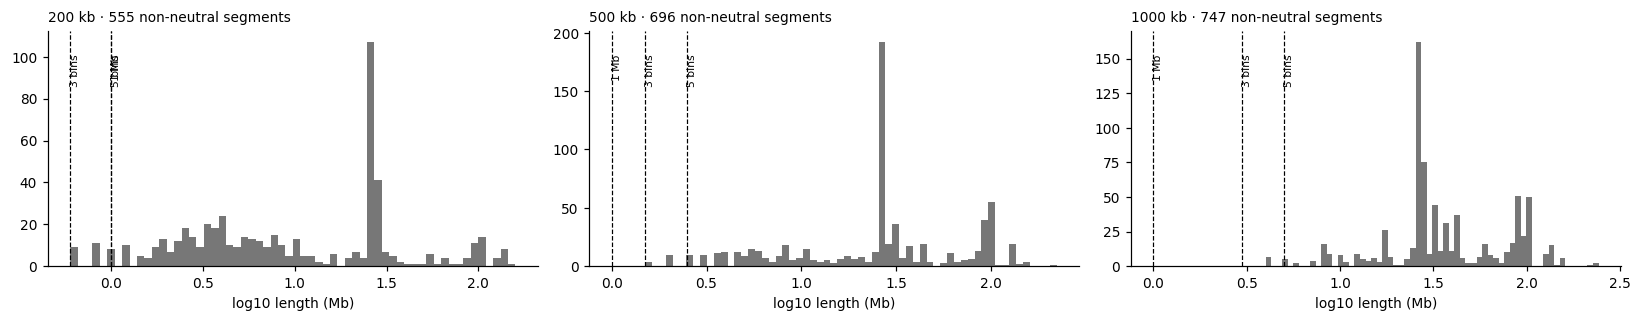

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
for ax, b in zip(axes, BINS):
    okc = set(qc[b].cell_id[qc[b].depth_ok == 1])
    s = seg[b][seg[b].cell_id.isin(okc) & ((seg[b].rel > 1.3) | (seg[b].rel < 0.7))]
    ax.hist(np.log10(s.len_mb), bins=60, color="#777777")
    for v, lab in ((1, "1 Mb"), (3 * b / 1000, "3 bins"), (5 * b / 1000, "5 bins")):
        ax.axvline(np.log10(v), ls="--", lw=.8, color="k"); ax.text(np.log10(v), ax.get_ylim()[1]*.9, lab, fontsize=7, rotation=90, va="top")
    ax.set_title(f"{b} kb · {len(s)} non-neutral segments", loc="left"); ax.set_xlabel("log10 length (Mb)")
plt.tight_layout(); plt.show()

### 3.4 The same cell in the three bins

Example altered cells from each donor. A real event appears in all three bins; a noise artefact usually appears only at 200 kb.

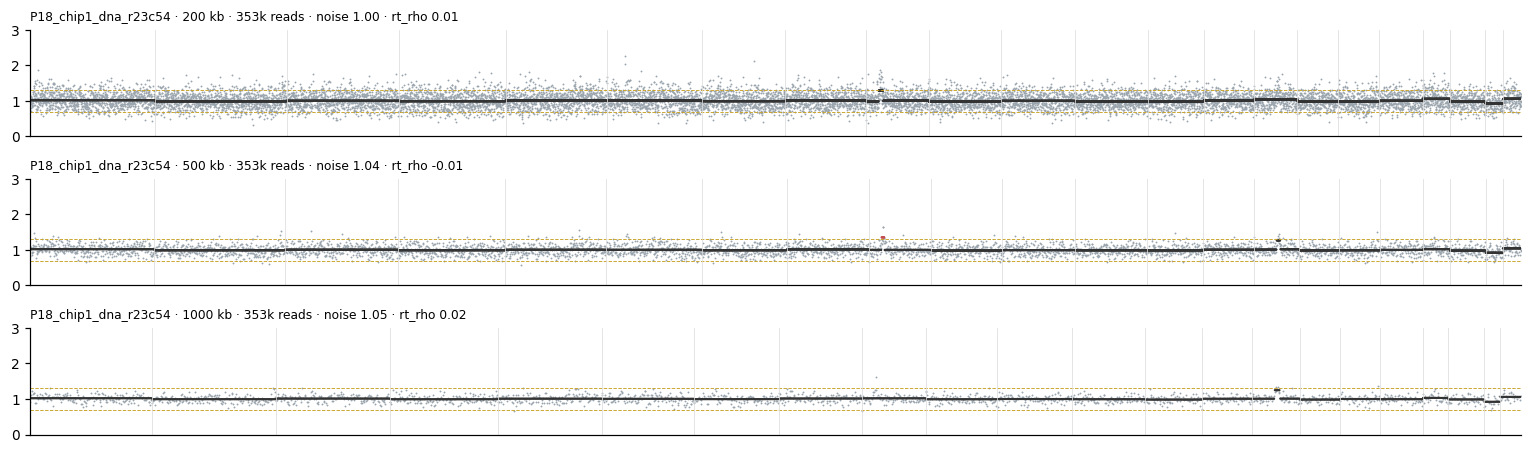

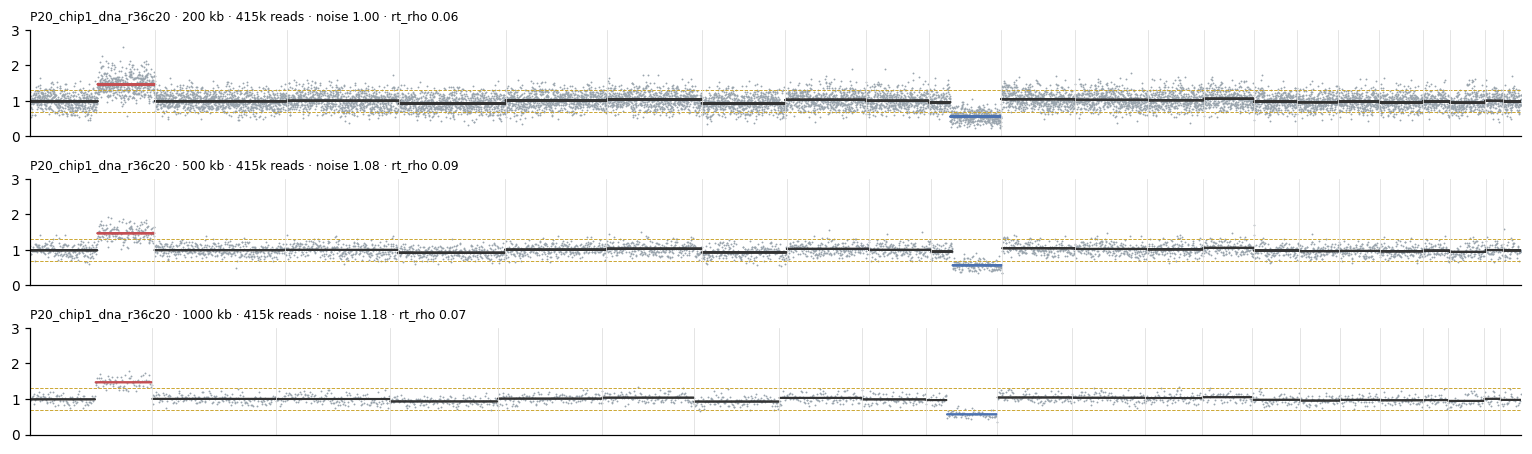

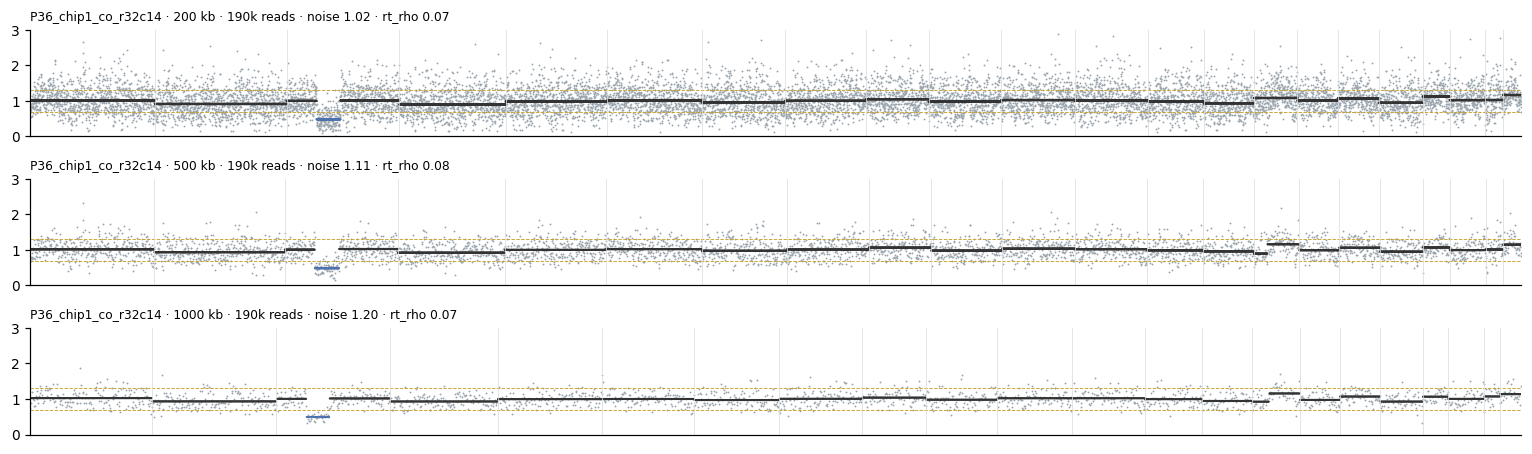

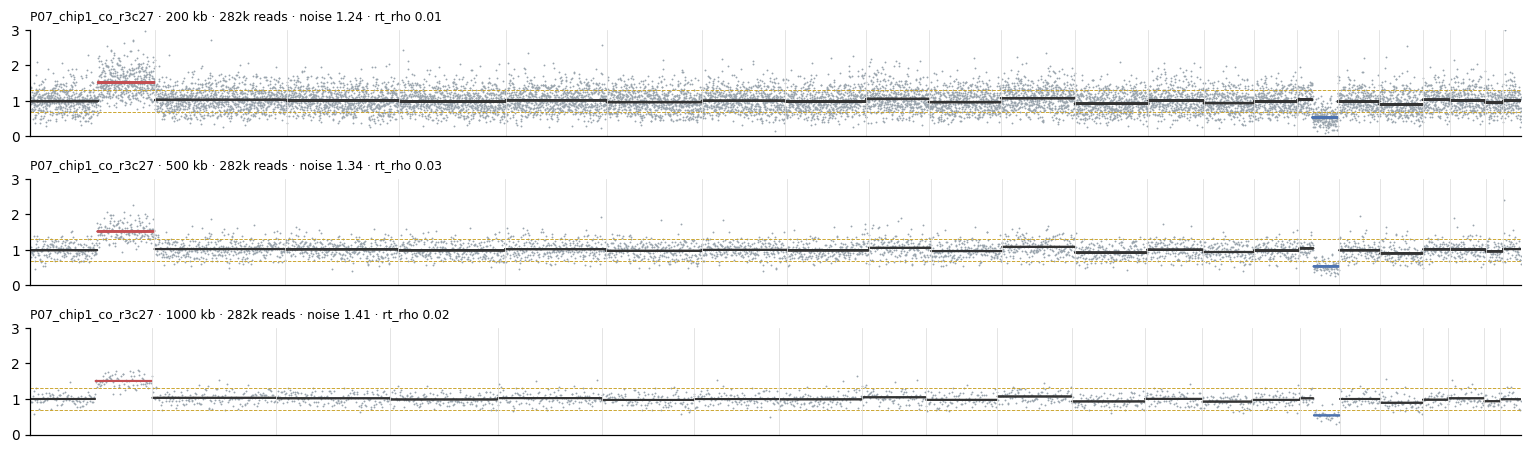

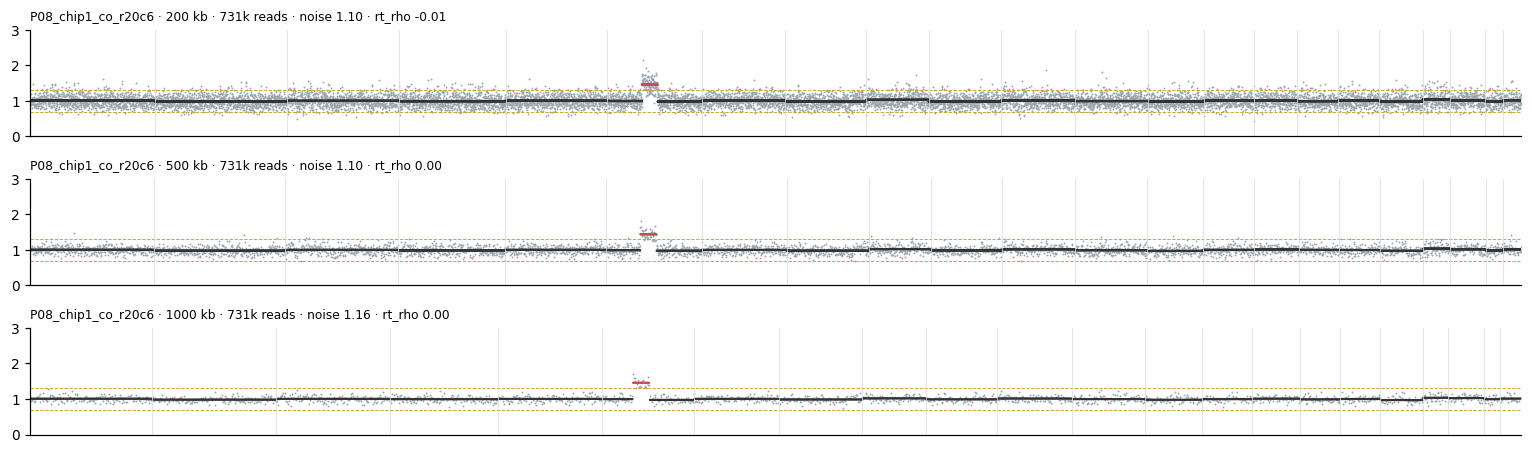

In [20]:
alt_ex = examples[examples.tags.str.contains("altered")]
pick = [alt_ex[alt_ex.donor == d].cell_id.iloc[0] for d in DONORS if (alt_ex.donor == d).any()]
for c in pick:
    fig, axes = plt.subplots(3, 1, figsize=(14, 4.2))
    for ax, b in zip(axes, BINS):
        plot_profile(c, b, ax)
    plt.tight_layout(); plt.show()

## 4 · Explore any cell

Set `CELL` to any `cell_id` in `results/pilot_cn/notebook/example_cells.tsv`; the `tags` column says why it was picked. Other cells must first be exported with `export_relcn.R --cells`.

donor         
P07    random      8
       batch       8
       altered     8
       noisy       6
       rt          6
       shallow     4
P08    random      8
       batch       8
       altered     8
       noisy       6
       rt          6
       shallow     4
P18    random      8
       batch       4
       altered     8
       noisy       6
       rt          6
       shallow     4
P20    random      8
       batch      27
       altered     8
       noisy       6
       rt          6
       shallow     4
P36    random      8
       batch       4
       altered     8
       noisy       6
       rt          6
       shallow     4
Name: tags, dtype: int64

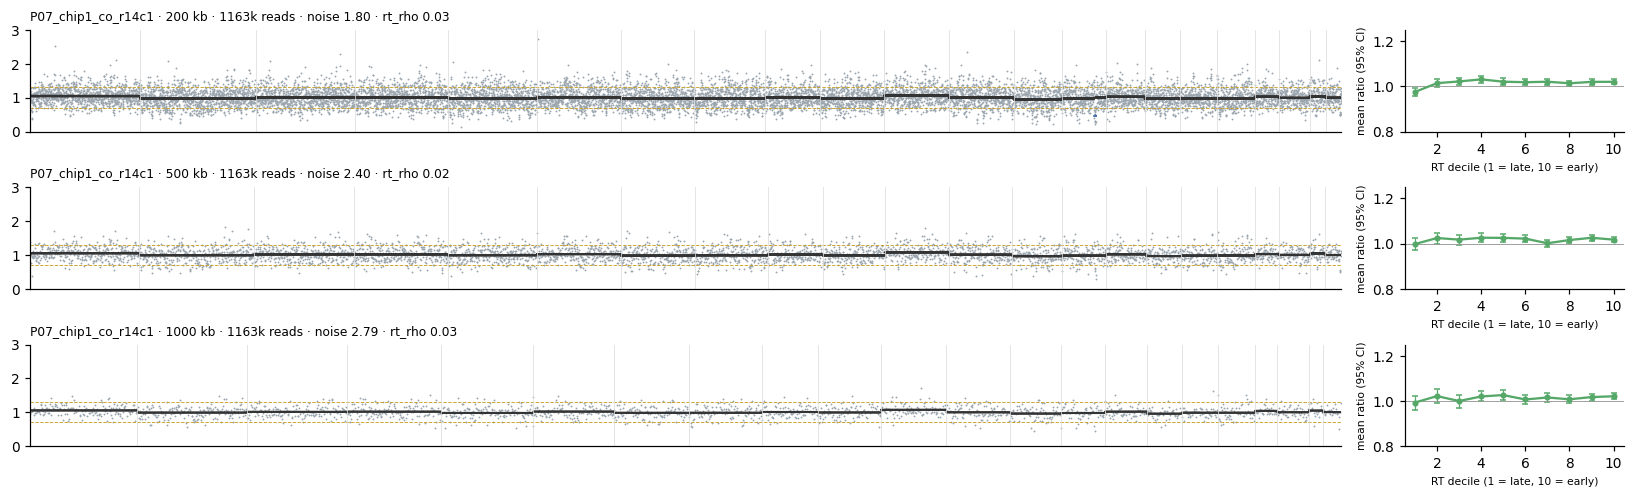

In [21]:
display(examples.groupby(["donor"]).tags.apply(lambda t: t.str.split(",").explode().value_counts().to_dict()))
CELL = examples[examples.tags.str.contains("noisy")].cell_id.iloc[0]
fig, axes = plt.subplots(3, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [6, 1]})
for (ax, axd), b in zip(axes, BINS):
    plot_profile(CELL, b, ax); plot_rt_deciles(CELL, b, axd)
plt.tight_layout(); plt.show()

## 5 · Decisions

| Question | Paper | What the data show | Options considered | Decided (2026-11-04) |
|---|---|---|---|---|
| Noise | > 15 breakpoints and outliers by correlation | The extra noise belongs to the P07 co-assay batch, not to the instrument or depth | (a) the paper's criterion; (b) batch-relative `noise_excess` + cap; (c) both | `noise_excess` ≤ 1.5 |
| S phase | Not handled | P20 is shifted as a whole donor (batch bias); real tails in P07 | (a) not handled, as in the paper; (b) fixed cut 0.10; (c) batch-centred | `rt_rho` ≤ 0.10 |
| Ratio | 1.3 / 0.7 | The sweep is flat; P18 1.4–2.4% altered | Keep 1.3 / 0.7, as in the paper | 1.3 / 0.7 |
| Minimum segment | None | Almost no short altered segments; the rule changes little | Keep ≥ 1 Mb or drop it, as in the paper | ≥ 1 Mb |